<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h1 style="color:#0F2A4A">نوت‌بوک ۵ — مقایسه پنج روش</h1>
<h2 style="color:#0E7490">Model Comparison on Iris</h2>
<p>هر پنج الگوریتم ارائه‌شده را روی <b>همان تقسیم آموزش/آزمون</b> (۸۵/۱۵، random_state=42) مقایسه می‌کنیم.</p>
<p>در این نوت‌بوک:</p>
<ul><li>دقت آزمون همه مدل‌ها</li><li>نمودار مقایسه</li><li>جدول نقاط قوت و ضعف</li></ul>
<p style="color:#45607A; font-size:13px">همراه ارائه درس «داده‌کاوی و یادگیری ماشین» — برای اجرا در Google Colab: هر سلول را با <b>Shift+Enter</b> اجرا کنید و پارامترها را آزادانه تغییر دهید.</p>
<hr style="border:0;border-top:1px dashed #B7DFEA;margin:10px 0">
<p style="background:#EBF7FA;border:1px solid #B7DFEA;border-radius:8px;padding:10px 12px">
🛠 <b>راهنمای استفاده:</b> همهٔ کدها در <b>Google Colab</b> اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: <b>Shift+Enter</b> یا منوی Runtime ▸ Run all).<br>
🐍 <b>یادگیری پایتون، از صفر:</b> <a href="https://www.w3schools.com/python/default.asp">W3Schools — Python Tutorial</a> — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.<br>
📝 <b>هر سلول:</b> توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.
</p>
</div>

In [1]:
# تنظیمات اولیه: واردکردن کتابخانه‌ها + پالت رنگی و ظاهر یکسان نمودارها
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TEAL, NAVY, AMBER = "#0E7490", "#0F2A4A", "#B45309"
plt.rcParams.update({"figure.facecolor":"white","axes.grid":True,"grid.color":"#D8E2EC",
    "axes.edgecolor":"#94A3B8","axes.labelcolor":"#0F2A4A","text.color":"#0F2A4A",
    "axes.titlecolor":"#0F2A4A","axes.titleweight":"bold","legend.frameon":False,
    "xtick.color":"#334155","ytick.color":"#334155"})
print("libraries ready")

libraries ready


In [2]:
# آموزش هر ۵ مدل روی همان تقسیم Iris — همه با شرایط یکسان (پیام: No Free Lunch)
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.15,
                                          random_state=42, stratify=y)
models = {
    "KNN (k=5)":        KNeighborsClassifier(5),
    "Decision Tree":    DecisionTreeClassifier(max_depth=3, random_state=42),
    "Gaussian NB":      GaussianNB(),
    "SVM (RBF)":        SVC(random_state=42),
    "Neural Net (16)":  MLPClassifier(hidden_layer_sizes=(16,), max_iter=3000,
                                      random_state=42),
}
results = {}
for name, model in models.items():
    results[name] = model.fit(X_tr, y_tr).score(X_te, y_te)
    print(f"{name:<16} test accuracy = {results[name]:.3f}")

KNN (k=5)        test accuracy = 1.000
Decision Tree    test accuracy = 0.957
Gaussian NB      test accuracy = 0.913
SVM (RBF)        test accuracy = 0.913
Neural Net (16)  test accuracy = 1.000


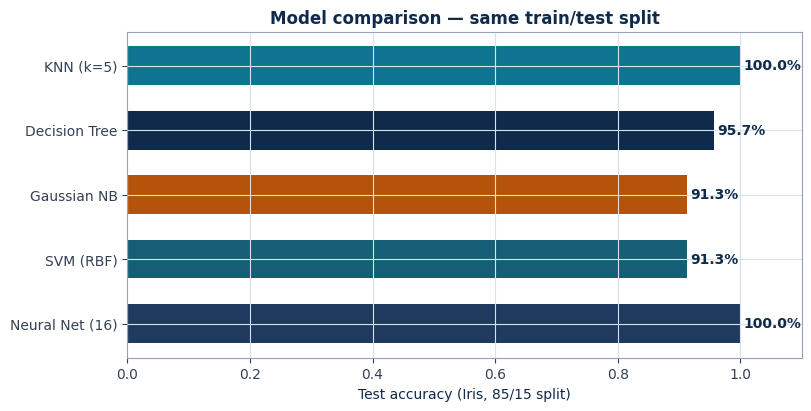

In [3]:
# نمودار مقایسهٔ ۵ مدل — همان شکل اسلاید پشتیبان ۲
fig, ax = plt.subplots(figsize=(8,4), layout="constrained")
names = list(results); vals = [results[n] for n in names]
bars = ax.barh(names[::-1], vals[::-1], color=[TEAL,NAVY,AMBER,"#155E75","#1E3A5F"][::-1], height=.6)
for b, v in zip(bars, vals[::-1]):
    ax.text(v+.005, b.get_y()+b.get_height()/2, f"{v:.1%}", va="center", fontweight="bold")
ax.set_xlim(0,1.1); ax.set_xlabel("Test accuracy (Iris, 85/15 split)")
ax.set_title("Model comparison — same train/test split")
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">نکته پایانی: کدام الگوریتم؟</h2>
<table style="border-collapse:collapse" border="1">
<tr style="background:#0F2A4A;color:white"><th>روش</th><th>نقطه قوت</th><th>نکته قابل توجه</th></tr>
<tr><td>KNN</td><td>ساده و شهودی، بدون آموزش</td><td>حساس به مقیاس و k</td></tr>
<tr><td>درخت تصمیم</td><td>کاملاً تفسیرپذیر، قوانین IF-THEN</td><td>مستعد بیش‌برازش</td></tr>
<tr><td>بیز</td><td>بسیار سریع، کم‌داده</td><td>فرض استقلال ویژگی‌ها</td></tr>
<tr><td>SVM</td><td>مؤثر در ابعاد بالا، کرنل غیرخطی</td><td>پرهزینه روی داده خیلی بزرگ</td></tr>
<tr><td>شبکه عصبی</td><td>روابط پیچیده غیرخطی</td><td>جعبه‌سیاه‌تر، نیازمند تنظیم</td></tr>
</table>
<p><b>هیچ الگوریتمی همیشه برنده نیست</b> — انتخاب به داده، حجم و نیاز به تفسیرپذیری بستگی دارد (No Free Lunch).</p>
</div>